# AI Agents for Variational Quantum Circuit Design: figures and tables

This notebook regenerates every data figure and every computed table of the paper from the
files shipped in this repository (agent run logs in `results/agent_runs/`, baseline results in
`results/baselines/`, the data set in `data/`). It does not train anything and runs in a few
minutes on a laptop CPU.

Outputs are written to `figures/paper/` with the file names used in the manuscript.

| Paper item | Section of this notebook |
|---|---|
| Fig. 3 (Gaussian peaks) | 1 |
| Figs. 4, 6, 8, 10 (agent trajectories) | 2 |
| Figs. 5, 7, 9, 11 (best circuits) | 3 |
| Fig. 13 (HEA scaling heatmap) | 4 |
| Tables 1, 3, 4 | 5 |
| Tables A1, A2 (validation re-selection, Welch tests) | 6 |
| Circuit size of the best Full Quantum circuit (Sec. 4.3) | 7 |
| Fig. 12 (Lie-EQGNN session) | 8 |

Not generated here: Figs. 1 and 2 are drawn schematics (PDFs in `figures/static/`);
Table 2 is a literature comparison and Table 5 was compiled by hand from the transcripts in
`results/transcripts/`.

Run it from the repository root (`jupyter lab paper_figures.ipynb`, or
`jupyter nbconvert --to notebook --execute paper_figures.ipynb`).

In [1]:
import glob
import shutil
import warnings
from pathlib import Path

import altair as alt
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import scienceplots  # noqa: F401  (registers the "science" matplotlib styles)
from IPython.display import display
from scipy.stats import spearmanr, ttest_ind

warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd()
assert (REPO / "results" / "agent_runs").is_dir(), "run this notebook from the repository root"
DATA = REPO / "data" / "gaussian_peak_noise_0_01"
RUNS = REPO / "results" / "agent_runs"
BASELINES = REPO / "results" / "baselines"
OUT = REPO / "figures" / "paper"
OUT.mkdir(parents=True, exist_ok=True)

# The paper figures use SciencePlots with LaTeX text rendering. Without a LaTeX installation
# we fall back to matplotlib's mathtext; the figures then differ only in the fonts.
USE_TEX = shutil.which("latex") is not None
PAPER_STYLE = ["science", "grid"] if USE_TEX else ["science", "grid", "no-latex"]
PAPER_RC = {
    "font.family": "sans-serif",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "cm",
    "font.size": 14,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "axes.linewidth": 1.8,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.fontsize": 14,
    "legend.frameon": False,
    "lines.linewidth": 3.2,
    "lines.markersize": 6,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
}


def paper_style():
    # Style context for the data figures (Figs. 3, 4, 6, 8, 10).
    return plt.style.context(PAPER_STYLE)


def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")
    print(f"wrote figures/paper/{name}")


def load_session(folder):
    # One parquet file per circuit evaluation; the time-sorted file order is the iteration index.
    files = sorted(glob.glob(str(RUNS / folder / "*.parquet")))
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    df["val_RMSE_final"] = df["val_MSE_hist"].apply(lambda h: float(np.sqrt(np.asarray(h)[-1])))
    return df


print("LaTeX text rendering:", USE_TEX)

LaTeX text rendering: True


## 1. Data set (Fig. 3)

Five training examples of the Gaussian-peak regression task (21 points, noise standard deviation
0.01). Dashed lines mark the peak positions, which are the regression targets.

wrote figures/paper/gaussian_peaks.pdf


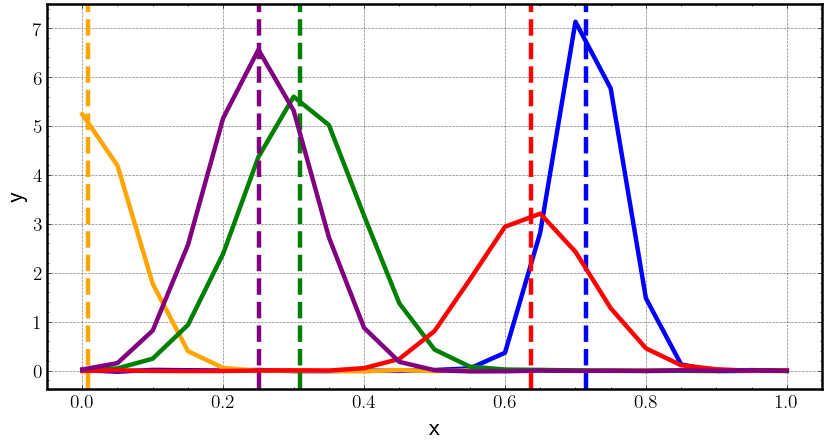

In [2]:
with h5py.File(DATA / "train.h5", "r") as f:
    X_train = f["X"][:10].squeeze(2)
    y_train = f["y"][:10]

with paper_style(), mpl.rc_context(PAPER_RC):
    fig = plt.figure(figsize=(10, 5))
    x = np.linspace(0, 1, X_train.shape[1])
    for i, color in enumerate(["blue", "orange", "green", "red", "purple"]):
        plt.plot(x, X_train[i], color=color, label=f"Event {i + 1}")
        plt.axvline(y_train[i, 0], color=color, linestyle="--")
    plt.xlabel("x")
    plt.ylabel("y")
    save(fig, "gaussian_peaks.pdf")
    plt.show()

## 2. Agent sessions (Figs. 4, 6, 8, 10)

For each reported session: (a) test RMSE against the number of trainable VQC parameters, with
arrows in iteration order; (b) test RMSE against the iteration index with two linear fits (all
iterations, and the best 70%). Stars and dashed lines mark the iterations after which we sent
the agent a message (the last iteration before each interaction, 0-based, checked against the
transcripts).

| Session (log folder) | LLM | Architecture | Figure |
|---|---|---|---|
| `SimpleQNN_runs_log_Sonnet_3_7_2025_11_17_02` | Claude 3.7 Sonnet | Simple QNN | 4 |
| `SimpleQNN_runs_log_LLama3_3_2025_11_21` | Llama 3.3 70B | Simple QNN | 6 |
| `FullQuantum_runs_log_LLama3_3_2025_11_21` | Llama 3.3 70B | Full Quantum | 8 |
| `QuanvNN_runs_log_LLama3_3_2025_11_24` | Llama 3.3 70B | Quanvolutional | 10 |

Claude 3.7 Sonnet, Simple QNN: 26 iterations, best test RMSE 0.0326 (iteration 25)


wrote figures/paper/CS37_SimpleQNN_test_RMSE_vs_n_params.pdf
wrote figures/paper/CS37_SimpleQNN_test_RMSE_vs_index.pdf


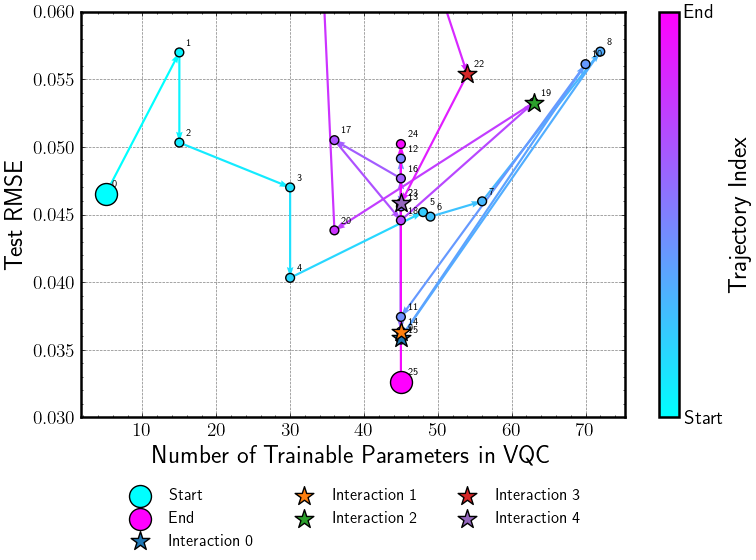

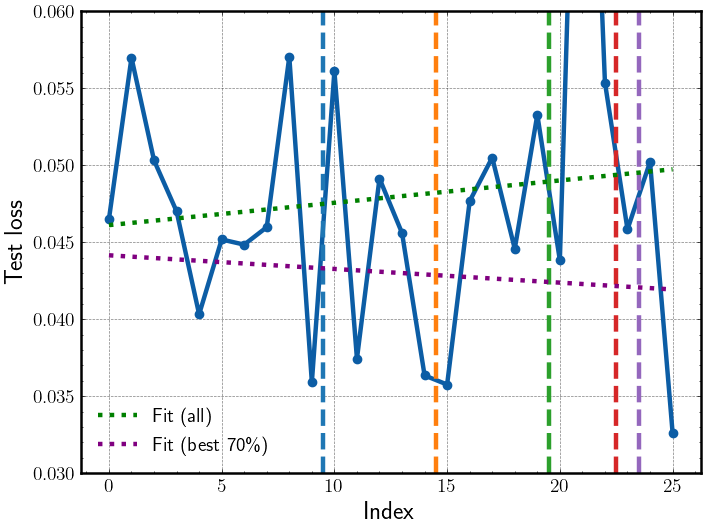

Llama 3.3 70B, Simple QNN: 26 iterations, best test RMSE 0.0207 (iteration 20)


wrote figures/paper/LL_SimpleQNN_test_RMSE_vs_n_params.pdf
wrote figures/paper/LL_SimpleQNN_test_RMSE_vs_index.pdf


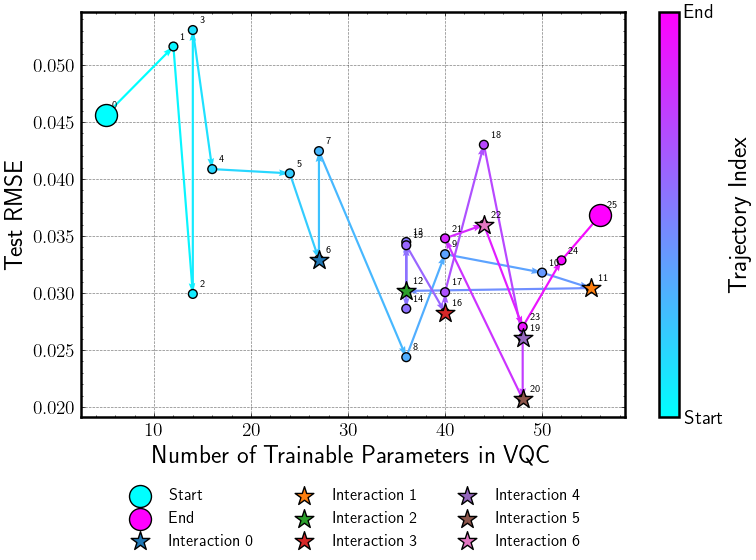

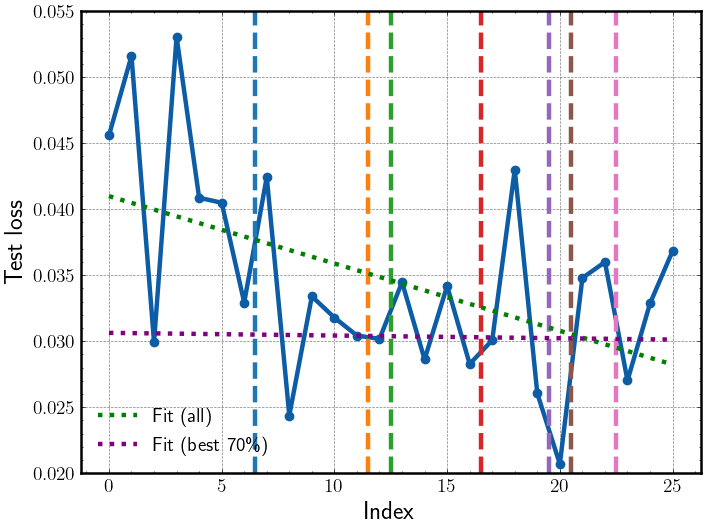

Llama 3.3 70B, Full Quantum: 17 iterations, best test RMSE 0.0811 (iteration 16)


wrote figures/paper/LL_FullQuantum_test_RMSE_vs_n_params.pdf
wrote figures/paper/LL_FullQuantum_test_RMSE_vs_index.pdf


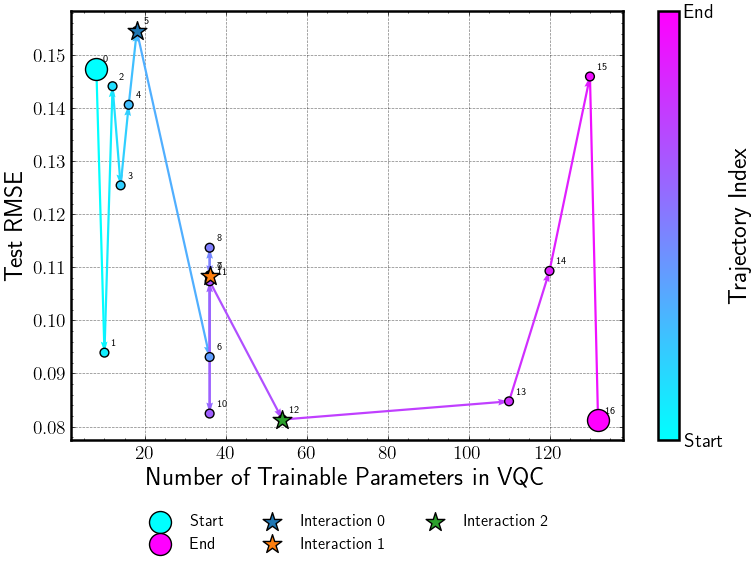

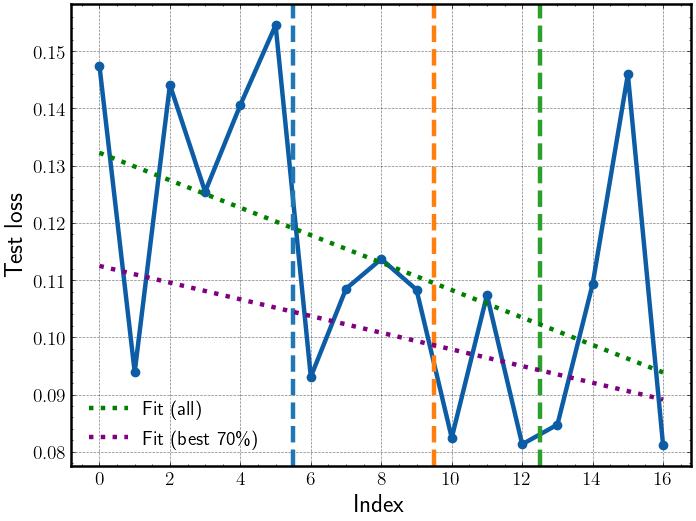

Llama 3.3 70B, Quanvolutional: 25 iterations, best test RMSE 0.1330 (iteration 12)


wrote figures/paper/LL_Quanv_test_RMSE_vs_n_params.pdf
wrote figures/paper/LL_Quanv_test_RMSE_vs_index.pdf


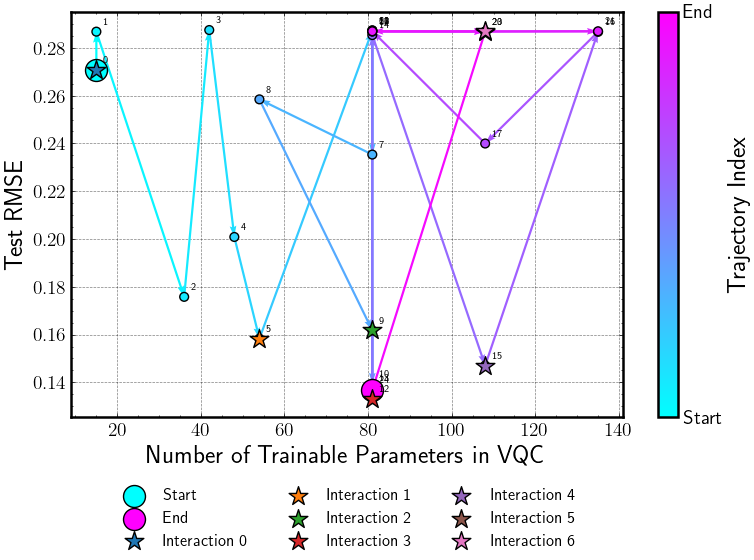

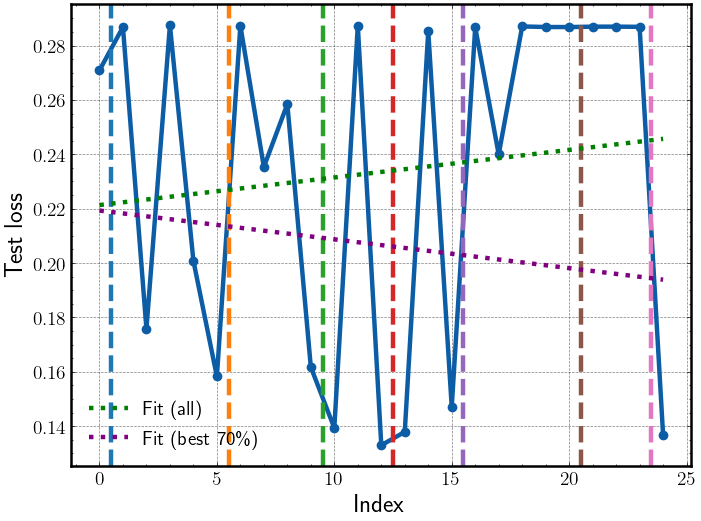

In [3]:
# (log folder, file prefix, interaction indices, y-limits of panel (a), y-limits of panel (b))
SESSIONS = {
    "Claude 3.7 Sonnet, Simple QNN": (
        "SimpleQNN_runs_log_Sonnet_3_7_2025_11_17_02", "CS37_SimpleQNN",
        [9, 14, 19, 22, 23], (0.03, 0.06), (0.03, 0.06),
    ),
    "Llama 3.3 70B, Simple QNN": (
        "SimpleQNN_runs_log_LLama3_3_2025_11_21", "LL_SimpleQNN",
        [6, 11, 12, 16, 19, 20, 22], None, (0.02, 0.055),
    ),
    "Llama 3.3 70B, Full Quantum": (
        "FullQuantum_runs_log_LLama3_3_2025_11_21", "LL_FullQuantum",
        [5, 9, 12], None, None,
    ),
    "Llama 3.3 70B, Quanvolutional": (
        "QuanvNN_runs_log_LLama3_3_2025_11_24", "LL_Quanv",
        [0, 5, 9, 12, 15, 20, 23], None, None,
    ),
}
INTERACTION_COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink"]


def plot_rmse_vs_params(df, interactions, ylim):
    x = df["n_trainable_params_VQC"].to_numpy()
    y = df["test_RMSE"].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 6))
    n = len(x)
    norm = mpl.colors.Normalize(vmin=0, vmax=n - 1)
    cmap = plt.cm.cool
    colors = cmap(norm(np.arange(n)))
    ax.quiver(x[:-1], y[:-1], np.diff(x), np.diff(y), angles="xy", scale_units="xy", scale=1,
              color=colors[:-1], width=0.004)
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.annotate(str(i), (xi, yi), textcoords="offset points", xytext=(5, 5), ha="left", fontsize=7)
    ax.scatter(x, y, c=colors, s=40, edgecolor="k")
    ax.scatter(x[0], y[0], color=colors[0], label="Start", s=250, edgecolor="k", marker="o")
    ax.scatter(x[-1], y[-1], color=colors[-1], label="End", s=250, edgecolor="k", marker="o")
    for k, it in enumerate(interactions):
        ax.scatter(x[it], y[it], color=INTERACTION_COLORS[k], label=f"Interaction {k}", s=200,
                   edgecolor="k", marker="*")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize="small")
    ax.set_xlabel("Number of Trainable Parameters in VQC")
    ax.set_ylabel("Test RMSE")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, ticks=[0, n - 1])
    cbar.set_label("Trajectory Index")
    cbar.set_ticklabels(["Start", "End"])
    if ylim:
        ax.set_ylim(*ylim)
    fig.tight_layout()
    return fig


def plot_rmse_vs_index(df, interactions, ylim):
    y = df["test_RMSE"].to_numpy()
    x = np.arange(len(y))
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(x, y, marker="o")
    for k, it in enumerate(interactions):
        ax.axvline(it + 0.5, c=INTERACTION_COLORS[k], ls="--")
    m_all, b_all = np.polyfit(x, y, deg=1)
    ax.plot(x, m_all * x + b_all, color="green", ls=":", label="Fit (all)")
    mask = y <= np.quantile(y, 0.7)  # lower is better: keep the best 70%
    m_q, b_q = np.polyfit(x[mask], y[mask], deg=1)
    pct = r"70\%" if USE_TEX else "70%"
    ax.plot(x, m_q * x + b_q, color="purple", ls=":", label=f"Fit (best {pct})")
    ax.set_xlabel("Index")
    ax.set_ylabel("Test loss")
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend()
    return fig


sessions = {}
for label, (folder, prefix, interactions, ylim_a, ylim_b) in SESSIONS.items():
    df = load_session(folder)
    sessions[label] = df
    print(f"{label}: {len(df)} iterations, best test RMSE {df['test_RMSE'].min():.4f} "
          f"(iteration {int(df['test_RMSE'].idxmin())})")
    with paper_style(), mpl.rc_context(PAPER_RC):
        fig_a = plot_rmse_vs_params(df, interactions, ylim_a)
        save(fig_a, f"{prefix}_test_RMSE_vs_n_params.pdf")
        fig_b = plot_rmse_vs_index(df, interactions, ylim_b)
        save(fig_b, f"{prefix}_test_RMSE_vs_index.pdf")
        plt.show()

## 3. Best circuits (Figs. 5, 7, 9, 11)

Each circuit is rebuilt from the logged `VQC_code` of its iteration and drawn with PennyLane's
matplotlib drawer. The inputs are set to 1, 2, ..., 21 and the weights to zero, so input uploads
can be told apart from trainable gates in the drawing. Fig. 9 shows only the first part of the
Full Quantum circuit (initial Hadamards, upload of input 1, the six recurrent-cell blocks, and
the upload of input 2); the full circuit has 21 such time steps.

In [4]:
DRAW_KW = dict(style="black_white", fontsize=30)
CIRCUIT_INPUTS = np.arange(1, 22, dtype=float)


def logged_tape(folder, iteration):
    row = sessions_by_folder[folder].iloc[iteration]
    namespace = {"qml": qml, "np": np}
    exec(row["VQC_code"], namespace)  # the logged circuit code from our own runs
    weights = np.zeros(tuple(int(k) for k in np.atleast_1d(row["VQC_weights_shape"])))
    return qml.workflow.construct_tape(namespace["circuit"])(CIRCUIT_INPUTS, weights)


def draw(ops, measurements, name, n_wires):
    fig, _ = qml.drawer.tape_mpl(qml.tape.QuantumScript(ops, measurements), wire_order=range(n_wires),
                                 show_all_wires=True, **DRAW_KW)
    save(fig, name)
    plt.close(fig)


def unique_measurements(measurements):
    # The Quanvolutional circuit measures each observable twice (18 outputs from 9 qubits).
    seen, out = set(), []
    for m in measurements:
        key = (type(m.obs).__name__, tuple(m.wires))
        if key not in seen:
            seen.add(key)
            out.append(m)
    return out


sessions_by_folder = {SESSIONS[k][0]: df for k, df in sessions.items()}

# Fig. 5: Claude 3.7 Sonnet, Simple QNN, iteration 25
tape = logged_tape("SimpleQNN_runs_log_Sonnet_3_7_2025_11_17_02", 25)
draw(tape.operations, tape.measurements, "CS37_SimpleQNN_best_circuit.pdf", 9)

# Fig. 7: Llama 3.3 70B, Simple QNN, iteration 20
tape = logged_tape("SimpleQNN_runs_log_LLama3_3_2025_11_21", 20)
draw(tape.operations, tape.measurements, "LL_SimpleQNN_circuit_20.pdf", 12)

# Fig. 9: Llama 3.3 70B, Full Quantum, iteration 16, first part up to the upload of input 2
tape = logged_tape("FullQuantum_runs_log_LLama3_3_2025_11_21", 16)
ops = tape.operations
cut = next(i for i, op in enumerate(ops)
           if op.name == "RY" and op.wires.tolist() == [0] and np.isclose(float(op.data[0]), CIRCUIT_INPUTS[1]))
assert cut + 1 == 10 + 199 + 1, f"unexpected cut position {cut}"
draw(ops[: cut + 1], [], "LL_FullQuantum_circuit_16_part.pdf", 11)

# Fig. 11: Llama 3.3 70B, Quanvolutional, iteration 12 (encoding, then three layers)
tape = logged_tape("QuanvNN_runs_log_LLama3_3_2025_11_24", 12)
assert len(tape.operations) == 18 + 3 * (9 + 18 + 18)
draw(tape.operations, unique_measurements(tape.measurements), "LL_Quanv_circuit_12.pdf", 9)

wrote figures/paper/CS37_SimpleQNN_best_circuit.pdf


wrote figures/paper/LL_SimpleQNN_circuit_20.pdf


wrote figures/paper/LL_FullQuantum_circuit_16_part.pdf


wrote figures/paper/LL_Quanv_circuit_12.pdf


## 4. Scaling sweep of the hardware-efficient ansatz (Fig. 13)

Mean test RMSE over seeds for every (qubits, layers) cell of the HEA sweep (JAX pipeline, 7
epochs). Only runs with status `ok` are used; runs that hit the time or memory limit are logged
with another status. Note: the CSV contains a duplicated seed-4 row in the cell (20 qubits,
L = 3), so this figure, like the published one, shows 0.0360 there; without the duplicate the
cell mean is 0.0365 (the value given in the text). The significance tests in Section 6 drop it.

In [5]:
sweep = pd.read_csv(BASELINES / "scaling_sweep_extended.csv")
scaling_mean = (
    sweep[sweep["status"] == "ok"]
    .groupby(["n_qubits", "n_layers"], as_index=False)
    .agg(mean_rmse=("test_rmse", "mean"), std_rmse=("test_rmse", "std"), n_seeds=("test_rmse", "size"))
)
base = alt.Chart(scaling_mean).encode(
    x=alt.X("n_qubits:O", title="Number of qubits"),
    y=alt.Y("n_layers:O", title="Number of layers", sort="descending"),
)
heat = base.mark_rect().encode(
    color=alt.Color("mean_rmse:Q", title="Mean test RMSE", scale=alt.Scale(scheme="viridis", reverse=True)),
    tooltip=[
        alt.Tooltip("n_qubits:O", title="Qubits"),
        alt.Tooltip("n_layers:O", title="Layers"),
        alt.Tooltip("mean_rmse:Q", title="Mean RMSE", format=".4f"),
        alt.Tooltip("std_rmse:Q", title="Std RMSE", format=".4f"),
        alt.Tooltip("n_seeds:Q", title="Seeds"),
    ],
)
text = base.mark_text(fontSize=9).encode(text=alt.Text("mean_rmse:Q", format=".3f"), color=alt.value("black"))
scaling_heatmap = (heat + text).properties(width=520, height=320, title="HEA scaling: mean test RMSE")
scaling_heatmap.save(OUT / "scaling_heatmap.pdf")
print("wrote figures/paper/scaling_heatmap.pdf")
scaling_heatmap

wrote figures/paper/scaling_heatmap.pdf


alt.LayerChart(...)

## 5. Comparison tables (Tables 1, 3, 4)

"Best RMSE" is the single best circuit found during the search (best-of-N, trained at the
agent's chosen budget of up to 20 epochs); "five-seed" retrains that circuit from scratch over
seeds 0-4 at 7 epochs. HEA and SEL were trained with the PyTorch pipeline; the agent reseeds,
random and evolutionary search with the JAX pipeline (see the footnote to Table 1 in the paper).

In [6]:
fixed = pd.read_csv(BASELINES / "fixed_ansatz_baselines.csv")
agent_jax = pd.read_csv(BASELINES / "agent_best_reseed.csv")
agent_pt7 = pd.read_csv(BASELINES / "agent_best_reseed_pytorch_7ep.csv")
agent_pt20 = pd.read_csv(BASELINES / "agent_best_reseed_pytorch_origep.csv")
random_search = pd.read_csv(BASELINES / "random_search_baseline.csv")
evo_search = pd.read_csv(BASELINES / "evolutionary_search_baseline.csv")
classical = pd.read_csv(BASELINES / "classical_baseline_simpleqnn.csv")

AGENT_LABEL = {"sonnet_3.7": "Claude 3.7 Sonnet", "llama_3.3": "Llama 3.3 70B"}


def mean_std(values):
    return f"{np.mean(values):.4f} ± {np.std(values, ddof=1):.4f}"


def agent_row(model, label):
    d = agent_jax[agent_jax["agent_model"] == model]
    return {"Method": label, "n": d["n_qubits"].iloc[0], "VQC params": d["trainable_vqc_params"].iloc[0],
            "Best RMSE": round(d["original_rmse"].iloc[0], 4), "Five-seed mean ± std": mean_std(d["test_rmse"])}


def fixed_row(ansatz, layers, label):
    d = fixed[(fixed["ansatz"] == ansatz) & (fixed["layers"] == layers)]
    return {"Method": label, "n": d["n_qubits"].iloc[0], "VQC params": d["trainable_vqc_params"].iloc[0],
            "Best RMSE": "--", "Five-seed mean ± std": mean_std(d["test_rmse"])}


def search_row(df, search_method, label):
    search = df[df["method"] == search_method]
    reseed = df[df["method"] == f"{search_method}_best_reseed"]
    best = search.loc[search["test_rmse"].idxmin()]
    assert (reseed["n_qubits"] == best["n_qubits"]).all()
    assert (reseed["trainable_vqc_params"] == best["trainable_vqc_params"]).all()
    return {"Method": label, "n": best["n_qubits"], "VQC params": best["trainable_vqc_params"],
            "Best RMSE": round(best["test_rmse"], 4), "Five-seed mean ± std": mean_std(reseed["test_rmse"])}


table1 = pd.DataFrame(
    [fixed_row("HEA", L, f"Hardware-efficient ansatz, L={L}") for L in (1, 2, 3, 5)]
    + [fixed_row("SEL", L, f"Strongly Entangling Layers, L={L}") for L in (1, 2)]
    + [agent_row("sonnet_3.7", "Agent-designed (Claude 3.7 Sonnet)"),
       agent_row("llama_3.3", "Agent-designed (Llama 3.3 70B)")]
)
print("Table 1: standard ansätze vs. agent-designed circuits (Simple QNN)")
display(table1)

table3 = pd.DataFrame([
    agent_row("llama_3.3", "Agent (Llama 3.3 70B)"),
    agent_row("sonnet_3.7", "Agent (Claude 3.7 Sonnet)"),
    search_row(random_search, "random", "Random search"),
    search_row(evo_search, "evolutionary", "Evolutionary search"),
    fixed_row("HEA", 5, "Best HEA (L=5)"),
    fixed_row("SEL", 2, "Best SEL (L=2)"),
])
print("Table 3: agent vs. automated search vs. best standard ansätze")
display(table3)

Table 1: standard ansätze vs. agent-designed circuits (Simple QNN)


,Method,n,VQC params,Best RMSE,Five-seed mean ± std
0,"Hardware-efficient ansatz, L=1",9,9,--,0.0459 ± 0.0107
1,"Hardware-efficient ansatz, L=2",9,18,--,0.0447 ± 0.0112
2,"Hardware-efficient ansatz, L=3",9,27,--,0.0393 ± 0.0033
3,"Hardware-efficient ansatz, L=5",9,45,--,0.0365 ± 0.0074
4,"Strongly Entangling Layers, L=1",9,27,--,0.0438 ± 0.0166
5,"Strongly Entangling Layers, L=2",9,54,--,0.0400 ± 0.0061
6,Agent-designed (Claude 3.7 Sonnet),9,45,0.0326,0.0496 ± 0.0174
7,Agent-designed (Llama 3.3 70B),12,48,0.0207,0.0311 ± 0.0051


Table 3: agent vs. automated search vs. best standard ansätze


,Method,n,VQC params,Best RMSE,Five-seed mean ± std
0,Agent (Llama 3.3 70B),12,48,0.0207,0.0311 ± 0.0051
1,Agent (Claude 3.7 Sonnet),9,45,0.0326,0.0496 ± 0.0174
2,Random search,6,18,0.028,0.0350 ± 0.0058
3,Evolutionary search,7,70,0.033,0.0370 ± 0.0052
4,Best HEA (L=5),9,45,--,0.0365 ± 0.0074
5,Best SEL (L=2),9,54,--,0.0400 ± 0.0061


In [7]:
# Table 4: contribution of the VQC. "Classical only" is the Simple QNN with the VQC removed;
# "With VQC" is the best agent circuit. Both PyTorch, same five seeds.
rows = []
for epochs, with_vqc in ((20, agent_pt20), (7, agent_pt7)):
    for model in ("sonnet_3.7", "llama_3.3"):
        q = with_vqc[with_vqc["agent_model"] == model]
        enc = int(q["q_enc_size"].iloc[0])
        # same classical model (enc = out = n_enc) and budget; at 7 epochs and n_enc = 5 this is
        # also the classical counterpart of the first Claude circuit (Appendix C)
        c = classical[(classical["q_enc_size"] == enc) & (classical["q_out_size"] == enc)
                      & (classical["epochs"] == epochs)]
        assert len(c) == 5 and len(q) == 5, (model, epochs, len(c), len(q))
        p = ttest_ind(c["test_rmse"], q["test_rmse"], equal_var=False).pvalue
        rows.append({
            "Best circuit of": AGENT_LABEL[model], "n_enc": enc, "Epochs": epochs,
            "Params (classical / with VQC)": f"{c['trainable_total_params'].iloc[0]} / {q['trainable_total_params'].iloc[0]}",
            "Classical only": mean_std(c["test_rmse"]), "With VQC": mean_std(q["test_rmse"]),
            "Reduction": f"{1 - q['test_rmse'].mean() / c['test_rmse'].mean():.0%}",
            "p (Welch)": "<0.001" if p < 0.001 else f"{p:.3f}" if p < 0.1 else f"{p:.2f}",
        })
table4 = pd.DataFrame(rows)
print("Table 4: contribution of the VQC in the Simple QNN")
display(table4)

Table 4: contribution of the VQC in the Simple QNN


,Best circuit of,n_enc,Epochs,Params (classical / with VQC),Classical only,With VQC,Reduction,p (Welch)
0,Claude 3.7 Sonnet,5,20,116 / 161,0.0468 ± 0.0029,0.0393 ± 0.0053,16%,0.029
1,Llama 3.3 70B,12,20,277 / 325,0.0399 ± 0.0020,0.0300 ± 0.0017,25%,<0.001
2,Claude 3.7 Sonnet,5,7,116 / 161,0.0486 ± 0.0044,0.0446 ± 0.0074,8%,0.34
3,Llama 3.3 70B,12,7,277 / 325,0.0421 ± 0.0031,0.0356 ± 0.0053,15%,0.053


## 6. Selection and significance checks (Tables A1, A2)

**Table A1.** For each session, the best circuit selected by test RMSE (as in the paper) and the
one that would have been selected by the final-epoch validation RMSE, plus Spearman's rank
correlation between validation and test RMSE over all circuits of the session and over the 8
circuits with the lowest test RMSE.

**Table A2.** Welch's t-test and the Welch 95% confidence interval of the difference of five-seed
means (agent minus baseline), only between methods trained with the same pipeline.

In [8]:
PAPER_BEST_ITERATION = {
    "Claude 3.7 Sonnet, Simple QNN": 25,
    "Llama 3.3 70B, Simple QNN": 20,
    "Llama 3.3 70B, Full Quantum": 16,
    "Llama 3.3 70B, Quanvolutional": 12,
}
rows = []
for label, df in sessions.items():
    it_test = int(df["test_RMSE"].idxmin())
    it_val = int(df["val_RMSE_final"].idxmin())
    assert it_test == PAPER_BEST_ITERATION[label]
    top8 = df.nsmallest(8, "test_RMSE")
    rows.append({
        "Session": label, "Iterations": len(df),
        "Test-sel. it.": it_test, "Test-sel. test RMSE": df["test_RMSE"][it_test],
        "Test-sel. val RMSE": df["val_RMSE_final"][it_test],
        "Val-sel. it.": it_val, "Val-sel. test RMSE": df["test_RMSE"][it_val],
        "Val-sel. val RMSE": df["val_RMSE_final"][it_val],
        "Spearman rho (all)": spearmanr(df["val_RMSE_final"], df["test_RMSE"])[0],
        "Spearman rho (top 8)": spearmanr(top8["val_RMSE_final"], top8["test_RMSE"])[0],
    })
tableA1 = pd.DataFrame(rows)
display(tableA1.round(4))

,Session,Iterations,Test-sel. it.,Test-sel. test RMSE,Test-sel. val RMSE,Val-sel. it.,Val-sel. test RMSE,Val-sel. val RMSE,Spearman rho (all),Spearman rho (top 8)
0,"Claude 3.7 Sonnet, Simple QNN",26,25,0.0326,0.0321,25,0.0326,0.0321,0.9009,0.9762
1,"Llama 3.3 70B, Simple QNN",26,20,0.0207,0.0206,20,0.0207,0.0206,0.9802,0.9286
2,"Llama 3.3 70B, Full Quantum",17,16,0.0811,0.0824,12,0.0813,0.0806,0.9828,0.9048
3,"Llama 3.3 70B, Quanvolutional",25,12,0.1330,0.1277,12,0.1330,0.1277,0.9977,0.9524


In [9]:
sweep_ok = sweep[sweep["status"] == "ok"].drop_duplicates(["ansatz", "n_qubits", "n_layers", "seed"], keep="last")


def hea_jax(n, L):
    return sweep_ok.query("ansatz == 'HEA' and n_qubits == @n and n_layers == @L")["test_rmse"].values


samples = {
    "Llama (JAX)": agent_jax.query("agent_model == 'llama_3.3'")["test_rmse"].values,
    "Claude (JAX)": agent_jax.query("agent_model == 'sonnet_3.7'")["test_rmse"].values,
    "Random search": random_search.query("method == 'random_best_reseed'")["test_rmse"].values,
    "Evolutionary search": evo_search.query("method == 'evolutionary_best_reseed'")["test_rmse"].values,
    "HEA n=9 L=5 (JAX)": hea_jax(9, 5),
    "HEA n=9 L=8 (JAX)": hea_jax(9, 8),
    "HEA n=12 L=8 (JAX)": hea_jax(12, 8),
    "Llama (PyTorch)": agent_pt7.query("agent_model == 'llama_3.3'")["test_rmse"].values,
    "Claude (PyTorch)": agent_pt7.query("agent_model == 'sonnet_3.7'")["test_rmse"].values,
    "HEA n=9 L=5 (PyTorch)": fixed.query("ansatz == 'HEA' and layers == 5")["test_rmse"].values,
    "SEL n=9 L=2 (PyTorch)": fixed.query("ansatz == 'SEL' and layers == 2")["test_rmse"].values,
}
for k, v in samples.items():
    assert len(v) == 5, f"{k}: expected 5 seeds, got {len(v)}"

COMPARISONS = [("JAX", a, b) for a in ("Llama (JAX)", "Claude (JAX)")
               for b in ("Random search", "Evolutionary search", "HEA n=9 L=5 (JAX)", "HEA n=9 L=8 (JAX)", "HEA n=12 L=8 (JAX)")]
COMPARISONS += [("PyTorch", a, b) for a in ("Llama (PyTorch)", "Claude (PyTorch)")
                for b in ("HEA n=9 L=5 (PyTorch)", "SEL n=9 L=2 (PyTorch)")]

rows = []
for pipeline, a, b in COMPARISONS:
    x, y = samples[a], samples[b]
    t = ttest_ind(x, y, equal_var=False)
    ci = t.confidence_interval(0.95)
    rows.append({"Pipeline": pipeline, "Agent": a, "Agent mean ± std": mean_std(x), "Baseline": b,
                 "Baseline mean ± std": mean_std(y), "Difference": x.mean() - y.mean(),
                 "95% CI low": ci.low, "95% CI high": ci.high, "p": t.pvalue})
tableA2 = pd.DataFrame(rows)
display(tableA2.round(4))

,Pipeline,Agent,Agent mean ± std,Baseline,Baseline mean ± std,Difference,95% CI low,95% CI high,p
0,JAX,Llama (JAX),0.0311 ± 0.0051,Random search,0.0350 ± 0.0058,-0.0039,-0.0119,0.0041,0.2879
1,JAX,Llama (JAX),0.0311 ± 0.0051,Evolutionary search,0.0370 ± 0.0052,-0.0059,-0.0134,0.0016,0.1082
2,JAX,Llama (JAX),0.0311 ± 0.0051,HEA n=9 L=5 (JAX),0.0358 ± 0.0030,-0.0047,-0.0110,0.0017,0.1243
3,JAX,Llama (JAX),0.0311 ± 0.0051,HEA n=9 L=8 (JAX),0.0321 ± 0.0024,-0.0010,-0.0072,0.0053,0.7176
4,JAX,Llama (JAX),0.0311 ± 0.0051,HEA n=12 L=8 (JAX),0.0385 ± 0.0065,-0.0074,-0.0159,0.0012,0.0822
5,JAX,Claude (JAX),0.0496 ± 0.0174,Random search,0.0350 ± 0.0058,0.0145,-0.0067,0.0358,0.1375
6,JAX,Claude (JAX),0.0496 ± 0.0174,Evolutionary search,0.0370 ± 0.0052,0.0126,-0.0087,0.0338,0.1850
7,JAX,Claude (JAX),0.0496 ± 0.0174,HEA n=9 L=5 (JAX),0.0358 ± 0.0030,0.0138,-0.0076,0.0352,0.1508
8,JAX,Claude (JAX),0.0496 ± 0.0174,HEA n=9 L=8 (JAX),0.0321 ± 0.0024,0.0175,-0.0039,0.0390,0.0867
9,JAX,Claude (JAX),0.0496 ± 0.0174,HEA n=12 L=8 (JAX),0.0385 ± 0.0065,0.0111,-0.0101,0.0323,0.2367


## 7. Size of the best Full Quantum circuit (Sec. 4.3)

Gate count, CNOT count and depth of the best Llama 3.3 70B Full Quantum circuit (iteration 16),
counted on the full tape, and the logged values of all iterations of that session.

In [10]:
tape = logged_tape("FullQuantum_runs_log_LLama3_3_2025_11_21", 16)
n_gates = len(tape.operations)
n_cnot = sum(op.name == "CNOT" for op in tape.operations)
print(f"iteration 16: {n_gates} gates, {n_cnot} CNOTs, depth {tape.graph.get_depth()}")
fq = sessions["Llama 3.3 70B, Full Quantum"]
fq[["epochs", "test_RMSE", "n_trainable_params_VQC", "n_gates_in_VQC", "depth_of_VQC"]].round(4)

iteration 16: 4189 gates, 1386 CNOTs, depth 1659


,epochs,test_RMSE,n_trainable_params_VQC,n_gates_in_VQC,depth_of_VQC
0,7,0.1474,8,276,147
1,7,0.0939,10,340,168
2,7,0.1441,12,404,189
3,7,0.1254,14,468,210
4,7,0.1406,16,532,231
5,7,0.1546,18,596,252
6,7,0.0931,36,1163,483
7,7,0.1085,36,1163,483
8,7,0.1137,36,1163,483
9,7,0.1083,36,1163,483


## 8. Lie-EQGNN session (Fig. 12)

Claude 3.7 Sonnet on the Lie-EQGNN benchmark (Sec. 4.5; log folder
`LieEQGNN_runs_log_Sonnet_3_7_2025_12_23`): (a) test AUC against the number of trainable VQC
parameters, with arrows in iteration order; (b) test cross-entropy loss against the iteration
index with two linear fits (all iterations, and the best 70%). The model has five VQCs (the same
design with separate weights), so the parameter count is the sum over the five. The session had
three phases of 10, 10 and 2 iterations; stars and dashed lines mark the last iteration before
each of our two messages. Iteration 2 (test AUC 0.5) lies below the y-range of panel (a), as in
the paper.

22 iterations, best test AUC 0.7339 (iteration 15, 360 VQC parameters)


wrote figures/paper/CS37_Lie_test_auc_vs_n_params.png
wrote figures/paper/CS37_Lie_test_loss_vs_index.png


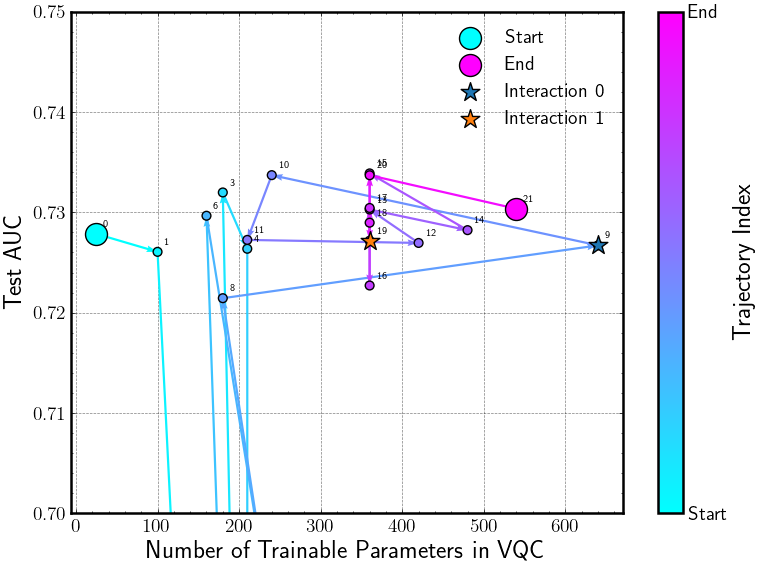

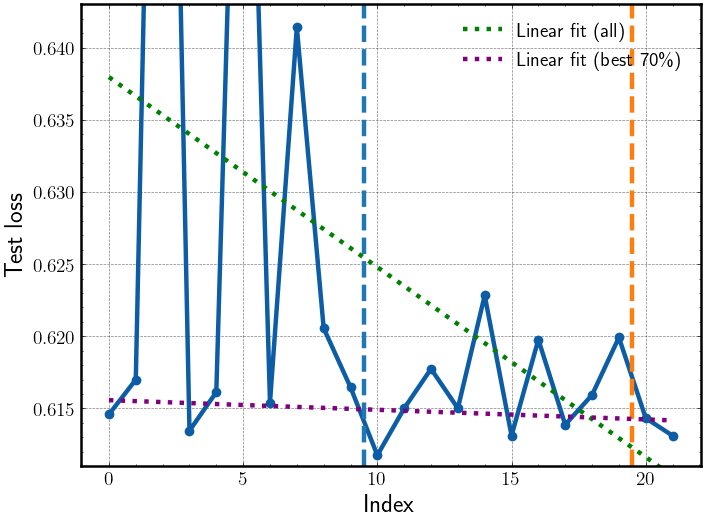

In [11]:
LIE_FOLDER = "LieEQGNN_runs_log_Sonnet_3_7_2025_12_23"
LIE_INTERACTIONS = [9, 19]

lie_files = sorted(glob.glob(str(RUNS / LIE_FOLDER / "*.parquet")))
lie = pd.concat([pd.read_parquet(f) for f in lie_files], ignore_index=True)
# n_trainable_params_VQC holds one entry per VQC in the model; the figure uses their sum.
lie["n_params_VQC_total"] = lie["n_trainable_params_VQC"].apply(
    lambda d: sum(v for v in d.values() if v is not None)
)
best = int(lie["test_auc"].idxmax())
print(f"{len(lie)} iterations, best test AUC {lie['test_auc'].max():.4f} (iteration {best}, "
      f"{lie['n_params_VQC_total'][best]} VQC parameters)")


def plot_lie_auc_vs_params(df, interactions):
    x = df["n_params_VQC_total"].to_numpy()
    y = df["test_auc"].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 6))
    n = len(x)
    norm = mpl.colors.Normalize(vmin=0, vmax=n - 1)
    cmap = plt.cm.cool
    colors = cmap(norm(np.arange(n)))
    ax.quiver(x[:-1], y[:-1], np.diff(x), np.diff(y), angles="xy", scale_units="xy", scale=1,
              color=colors[:-1], width=0.004)
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.annotate(str(i), (xi, yi), textcoords="offset points", xytext=(5, 5), ha="left", fontsize=7)
    ax.scatter(x, y, c=colors, s=40, edgecolor="k")
    ax.scatter(x[0], y[0], color=colors[0], label="Start", s=250, edgecolor="k", marker="o")
    ax.scatter(x[-1], y[-1], color=colors[-1], label="End", s=250, edgecolor="k", marker="o")
    for k, it in enumerate(interactions):
        ax.scatter(x[it], y[it], color=INTERACTION_COLORS[k], label=f"Interaction {k}", s=200,
                   edgecolor="k", marker="*")
    ax.legend()
    ax.set_xlabel("Number of Trainable Parameters in VQC")
    ax.set_ylabel("Test AUC")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, ticks=[0, n - 1])
    cbar.set_label("Trajectory Index")
    cbar.set_ticklabels(["Start", "End"])
    ax.set_ylim(0.70, 0.75)
    fig.tight_layout()
    return fig


def plot_lie_loss_vs_index(df, interactions):
    y = df["test_loss"].to_numpy()
    x = np.arange(len(y))
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(x, y, marker="o")
    for k, it in enumerate(interactions):
        ax.axvline(it + 0.5, c=INTERACTION_COLORS[k], ls="--")
    m_all, b_all = np.polyfit(x, y, deg=1)
    ax.plot(x, m_all * x + b_all, color="green", ls=":", label="Linear fit (all)")
    mask = y < np.quantile(y, 0.7)  # lower is better: keep the best 70%
    m_q, b_q = np.polyfit(x[mask], y[mask], deg=1)
    pct = r"70\%" if USE_TEX else "70%"
    ax.plot(x, m_q * x + b_q, color="purple", ls=":", label=f"Linear fit (best {pct})")
    ax.set_xlabel("Index")
    ax.set_ylabel("Test loss")
    ax.set_ylim(0.611, 0.643)
    ax.legend()
    return fig


with paper_style(), mpl.rc_context(PAPER_RC):
    fig_a = plot_lie_auc_vs_params(lie, LIE_INTERACTIONS)
    save(fig_a, "CS37_Lie_test_auc_vs_n_params.png")
    fig_b = plot_lie_loss_vs_index(lie, LIE_INTERACTIONS)
    save(fig_b, "CS37_Lie_test_loss_vs_index.png")
    plt.show()